<a href="https://colab.research.google.com/github/KtoxTheNisa/GROUP51_CENG313/blob/main/assignment1_eda_baseline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Rohlik Sales Forecasting – Assignment 1: EDA and Baselines

**Group 51** – CENG313 Introduction to Data Science

The goal of the competition is to predict daily sales of each product in each Rohlik warehouse for the 14 days after the training data ends. Submissions are scored with WMAE (weighted mean absolute error), where each product has a weight given in `test_weights.csv`.

In this notebook we:
1. Load and check the data
2. Clean it (missing values, wrong discounts, different price scales)
3. Explore the data with plots
4. Build a validation setup similar to the test period
5. Compare simple baseline models and submit the best one to Kaggle

## 1. Setup

Download the competition data with the Kaggle API. The token is stored in Colab secrets as `KAGGLE_API_TOKEN`.

In [54]:
import os
from google.colab import userdata
!rm -rf ~/.kaggle
!mkdir -p ~/.kaggle
token = userdata.get('KAGGLE_API_TOKEN')
with open('/root/.kaggle/access_token', 'w') as f:
  f.write(token)
!chmod 600 ~/.kaggle/access_token
print ("Done.")


Done.


In [55]:
!git clone https://github.com/KtoxTheNisa/GROUP51_CENG313.git
%cd GROUP51_CENG313

Cloning into 'GROUP51_CENG313'...
remote: Enumerating objects: 111, done.
remote: Counting objects: 100% (111/111), done.
remote: Compressing objects: 100% (91/91), done.
remote: Total 111 (delta 58), reused 54 (delta 18), pack-reused 0 (from 0)
Receiving objects: 100% (111/111), 985.73 KiB | 12.02 MiB/s, done.
Resolving deltas: 100% (58/58), done.
/content/GROUP51_CENG313/GROUP51_CENG313


In [56]:
!kaggle competitions download -c rohlik-sales-forecasting-challenge-v2

!unzip -q rohlik-sales-forecasting-challenge-v2.zip -d data

100% 47.3M/47.3M [00:00<00:00, 53.2MB/s]



Quick look at the raw training file to make sure the download worked.

In [57]:
import pandas as pd

df = pd.read_csv('data/sales_train.csv')
df.head()

,unique_id,date,warehouse,total_orders,sales,sell_price_main,availability,type_0_discount,type_1_discount,type_2_discount,type_3_discount,type_4_discount,type_5_discount,type_6_discount
0,4845,2024-03-10,Budapest_1,6436.0,16.34,646.26,1.00,0.00000,0.0,0.0,0.0,0.15312,0.0,0.0
1,4845,2021-05-25,Budapest_1,4663.0,12.63,455.96,1.00,0.00000,0.0,0.0,0.0,0.15025,0.0,0.0
2,4845,2021-12-20,Budapest_1,6507.0,34.55,455.96,1.00,0.00000,0.0,0.0,0.0,0.15025,0.0,0.0
3,4845,2023-04-29,Budapest_1,5463.0,34.52,646.26,0.96,0.20024,0.0,0.0,0.0,0.15312,0.0,0.0
4,4845,2022-04-01,Budapest_1,5997.0,35.92,486.41,1.00,0.00000,0.0,0.0,0.0,0.15649,0.0,0.0


Import libraries and our own helper functions. Loading, cleaning and merging are in `src/data.py`, the baseline models are in `src/models.py`, and the train/validation split, metrics and submission helper are in `src/utils.py`.

In [58]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from src.data import load_data, check_missing, clean_calendar, clean_sales, normalize_price, merge_tables
from src.models import predict_mean_baseline, predict_median_baseline, train_baseline_models, predict_ridge_baseline, predict_recent_mean_baseline, predict_recent_median_baseline
from src.utils import split_train_val, calculate_metrics, save_submission

## 2. Loading the Data
The dataset has 5 tables:
- `sales_train.csv`: daily sales of each product in each warehouse (the target is `sales`)
- `sales_test.csv`: the same columns without `sales` and `availability`, for the 14 test days
- `inventory.csv`: product information (product id and category names)
- `calendar.csv`: holidays and shop closures for each warehouse and date
- `test_weights.csv`: the weight of each product in the WMAE metric

In [59]:
#load all dataset tables
sales_train = load_data("data/sales_train.csv")
sales_test = load_data("data/sales_test.csv")
inventory = load_data("data/inventory.csv")
calendar = load_data("data/calendar.csv")
test_weights = load_data("data/test_weights.csv")

#check rows and columns for each table
print("sales_train shape:", sales_train.shape)
print("sales_test shape:", sales_test.shape)
print("inventory shape:", inventory.shape)
print("calendar shape:", calendar.shape)
print("test_weights shape:", test_weights.shape)

sales_train shape: (4007419, 14)
sales_test shape: (47021, 12)
inventory shape: (5432, 8)
calendar shape: (23016, 7)
test_weights shape: (5390, 2)


## 3. First Look at the Data

In [60]:
sales_train.head()

,unique_id,date,warehouse,total_orders,sales,sell_price_main,availability,type_0_discount,type_1_discount,type_2_discount,type_3_discount,type_4_discount,type_5_discount,type_6_discount
0,4845,2024-03-10,Budapest_1,6436.0,16.34,646.26,1.00,0.00000,0.0,0.0,0.0,0.15312,0.0,0.0
1,4845,2021-05-25,Budapest_1,4663.0,12.63,455.96,1.00,0.00000,0.0,0.0,0.0,0.15025,0.0,0.0
2,4845,2021-12-20,Budapest_1,6507.0,34.55,455.96,1.00,0.00000,0.0,0.0,0.0,0.15025,0.0,0.0
3,4845,2023-04-29,Budapest_1,5463.0,34.52,646.26,0.96,0.20024,0.0,0.0,0.0,0.15312,0.0,0.0
4,4845,2022-04-01,Budapest_1,5997.0,35.92,486.41,1.00,0.00000,0.0,0.0,0.0,0.15649,0.0,0.0


In [61]:
inventory.head()

,unique_id,product_unique_id,name,L1_category_name_en,L2_category_name_en,L3_category_name_en,L4_category_name_en,warehouse
0,5255,2583,Pastry_196,Bakery,Bakery_L2_14,Bakery_L3_26,Bakery_L4_1,Prague_3
1,4948,2426,Herb_19,Fruit and vegetable,Fruit and vegetable_L2_30,Fruit and vegetable_L3_86,Fruit and vegetable_L4_1,Prague_3
2,2146,1079,Beet_2,Fruit and vegetable,Fruit and vegetable_L2_3,Fruit and vegetable_L3_65,Fruit and vegetable_L4_34,Prague_1
3,501,260,Chicken_13,Meat and fish,Meat and fish_L2_13,Meat and fish_L3_27,Meat and fish_L4_5,Prague_1
4,4461,2197,Chicory_1,Fruit and vegetable,Fruit and vegetable_L2_17,Fruit and vegetable_L3_33,Fruit and vegetable_L4_1,Frankfurt_1


In [62]:
calendar.head()

,date,holiday_name,holiday,shops_closed,winter_school_holidays,school_holidays,warehouse
0,2022-03-16,NaN,0,0,0,0,Frankfurt_1
1,2020-03-22,NaN,0,0,0,0,Frankfurt_1
2,2018-02-07,NaN,0,0,0,0,Frankfurt_1
3,2018-08-10,NaN,0,0,0,0,Frankfurt_1
4,2017-10-26,NaN,0,0,0,0,Prague_2


In [63]:
sales_test.head()

,unique_id,date,warehouse,total_orders,sell_price_main,type_0_discount,type_1_discount,type_2_discount,type_3_discount,type_4_discount,type_5_discount,type_6_discount
0,1226,2024-06-03,Brno_1,8679.0,13.13,0.00000,0.0,0.0,0.0,0.0,0.0,0.0
1,1226,2024-06-11,Brno_1,8795.0,13.13,0.15873,0.0,0.0,0.0,0.0,0.0,0.0
2,1226,2024-06-13,Brno_1,10009.0,13.13,0.15873,0.0,0.0,0.0,0.0,0.0,0.0
3,1226,2024-06-15,Brno_1,8482.0,13.13,0.15873,0.0,0.0,0.0,0.0,0.0,0.0
4,1226,2024-06-09,Brno_1,8195.0,13.13,0.00000,0.0,0.0,0.0,0.0,0.0,0.0


In [64]:
test_weights.head()

,unique_id,weight
0,0,2.535369
1,1,3.888933
2,2,5.885237
3,3,2.139552
4,5,3.021715


In [65]:
#check unique product ids in inventory, train and test
print("Unique warehouse items (unique_id):", inventory["unique_id"].nunique())
print("Unique physical products (product_unique_id):", inventory["product_unique_id"].nunique())
print("Unique items in train:", sales_train["unique_id"].nunique())
print("Unique items in test:", sales_test["unique_id"].nunique())

Unique warehouse items (unique_id): 5432
Unique physical products (product_unique_id): 2670
Unique items in train: 5390
Unique items in test: 3625


`inventory.csv` has 5,432 `unique_id` rows, but only 2,670 `product_unique_id` values. The same product gets a different `unique_id` in each warehouse where it is sold.

In [66]:
sales_train.dtypes

,0
unique_id,int64
date,object
warehouse,object
total_orders,float64
sales,float64
sell_price_main,float64
availability,float64
type_0_discount,float64
type_1_discount,float64
type_2_discount,float64


In [67]:
sales_test.dtypes


,0
unique_id,int64
date,object
warehouse,object
total_orders,float64
sell_price_main,float64
type_0_discount,float64
type_1_discount,float64
type_2_discount,float64
type_3_discount,float64
type_4_discount,float64


In [68]:
inventory.dtypes


,0
unique_id,int64
product_unique_id,int64
name,object
L1_category_name_en,object
L2_category_name_en,object
L3_category_name_en,object
L4_category_name_en,object
warehouse,object


In [69]:
calendar.dtypes


,0
date,object
holiday_name,object
holiday,int64
shops_closed,int64
winter_school_holidays,int64
school_holidays,int64
warehouse,object


In [70]:
test_weights.dtypes

,0
unique_id,int64
weight,float64


In [71]:
sales_train.describe()


,unique_id,total_orders,sales,sell_price_main,availability,type_0_discount,type_1_discount,type_2_discount,type_3_discount,type_4_discount,type_5_discount,type_6_discount
count,4.007419e+06,4.007367e+06,4.007367e+06,4.007419e+06,4.007419e+06,4.007419e+06,4.007419e+06,4.007419e+06,4.007419e+06,4.007419e+06,4.007419e+06,4.007419e+06
mean,2.740801e+03,5.995722e+03,1.083808e+02,1.814199e+02,9.253107e-01,8.518626e-03,1.240899e-04,1.163193e-03,5.452819e-06,5.680178e-03,4.049705e-04,1.045480e-02
std,1.558566e+03,2.479598e+03,3.603327e+02,4.611014e+02,1.796205e-01,5.147027e-02,5.142815e-03,1.879977e-02,8.922436e-04,2.892965e-02,9.199913e-03,5.545035e-02
min,0.000000e+00,4.580000e+02,0.000000e+00,2.000000e-02,1.000000e-02,-2.094930e+01,0.000000e+00,0.000000e+00,0.000000e+00,-4.712000e-02,0.000000e+00,-8.014900e-01
25%,1.398000e+03,4.402000e+03,1.798000e+01,2.113000e+01,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
50%,2.744000e+03,5.515000e+03,3.952000e+01,4.564000e+01,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
75%,4.084000e+03,8.011000e+03,9.447000e+01,1.121300e+02,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
max,5.431000e+03,1.847500e+04,2.631619e+04,2.168299e+04,1.000000e+00,9.916400e-01,5.000000e-01,7.637200e-01,2.506300e-01,4.529000e-01,6.691400e-01,9.000500e-01


In [72]:
sales_test.describe()

,unique_id,total_orders,sell_price_main,type_0_discount,type_1_discount,type_2_discount,type_3_discount,type_4_discount,type_5_discount,type_6_discount
count,47021.000000,47021.000000,47021.000000,47021.000000,47021.000000,47021.000000,47021.0,47021.000000,47021.000000,47021.000000
mean,2749.678016,6880.911337,206.350987,0.013532,0.000251,0.004904,0.0,0.007142,0.000483,0.008359
std,1551.488719,2525.038306,525.128185,0.059923,0.007095,0.028592,0.0,0.032099,0.010956,0.043834
min,1.000000,1189.000000,0.130000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000
25%,1417.000000,5390.000000,20.110000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000
50%,2767.000000,6382.000000,49.040000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000
75%,4076.000000,8919.000000,120.580000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000
max,5431.000000,12374.000000,11084.520000,0.885580,0.201000,0.500630,0.0,0.357700,0.357650,0.900000


In [73]:
inventory.describe(include="all")

,unique_id,product_unique_id,name,L1_category_name_en,L2_category_name_en,L3_category_name_en,L4_category_name_en,warehouse
count,5432.000000,5432.000000,5432,5432,5432,5432,5432,5432
unique,NaN,NaN,2670,3,47,177,68,7
top,NaN,NaN,Rice Cake_2,Fruit and vegetable,Fruit and vegetable_L2_3,Fruit and vegetable_L3_33,Fruit and vegetable_L4_1,Budapest_1
freq,NaN,NaN,4,3282,1362,199,2522,949
mean,2715.500000,1344.782769,NaN,NaN,NaN,NaN,NaN,NaN
std,1568.227662,764.094002,NaN,NaN,NaN,NaN,NaN,NaN
min,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN
25%,1357.750000,690.000000,NaN,NaN,NaN,NaN,NaN,NaN
50%,2715.500000,1349.500000,NaN,NaN,NaN,NaN,NaN,NaN
75%,4073.250000,2002.000000,NaN,NaN,NaN,NaN,NaN,NaN


In [74]:
calendar.describe()

,holiday,shops_closed,winter_school_holidays,school_holidays
count,23016.000000,23016.000000,23016.000000,23016.000000
mean,0.042318,0.026590,0.011123,0.006648
std,0.201319,0.160886,0.104878,0.081263
min,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000
50%,0.000000,0.000000,0.000000,0.000000
75%,0.000000,0.000000,0.000000,0.000000
max,1.000000,1.000000,1.000000,1.000000


In [75]:
test_weights.describe()

,unique_id,weight
count,5390.000000,5390.000000
mean,2715.770686,4.055291
std,1568.004358,4.219848
min,0.000000,0.040065
25%,1359.250000,1.590774
50%,2716.500000,2.834906
75%,4071.750000,4.959406
max,5431.000000,73.281676


**Notes from `describe()`:**
- `sales` and `total_orders` have 52 fewer values than the other columns, so some rows are missing.
- `sales` goes from 0 to 26,316 but the median is only 39.5, so there are some very large values.
- `type_0_discount` has a minimum of -20.9. A discount should be between 0 and 1, so these values are wrong.
- `sell_price_main` has a very wide range. We look at this per warehouse below.
- `sales_test` has no negative discounts, and `test_weights` gives different weights to each product for WMAE.
- In `calendar`, `holiday` and `shops_closed` are 0/1 flags (around 4% of rows are holidays), and `inventory` has 3 main `L1` categories across 7 warehouses.

## 4. Data Quality Checks

### Missing values

In [76]:
print("sales_train missing values:")
print(check_missing(sales_train))
print("\nsales_test missing values:")
print(check_missing(sales_test))
print("\ninventory missing values:")
print(check_missing(inventory))
print("\ncalendar missing values:")
print(check_missing(calendar))
print("\ntest_weights missing values:")
print(check_missing(test_weights))

sales_train missing values:
total_orders    52
sales           52
dtype: int64

sales_test missing values:
Series([], dtype: int64)

inventory missing values:
Series([], dtype: int64)

calendar missing values:
holiday_name    22086
dtype: int64

test_weights missing values:
Series([], dtype: int64)


In [77]:
sales_train[sales_train["sales"].isnull()][["unique_id", "date", "warehouse", "total_orders", "sales"]].head()

,unique_id,date,warehouse,total_orders,sales
154017,885,2021-05-23,Munich_1,NaN,NaN
154099,885,2021-05-21,Munich_1,NaN,NaN
154149,885,2021-05-24,Munich_1,NaN,NaN
154155,885,2021-05-22,Munich_1,NaN,NaN
429815,1237,2021-12-10,Frankfurt_1,NaN,NaN


The 52 missing rows have both `sales` and `total_orders` missing, so we can't use them for training. We will drop them.

In the calendar, `holiday_name` is empty when the day is not a holiday, which is expected. We check how many names are missing on actual holidays.

In [78]:
#in calendar holiday_name is NaN by design when holiday is 0
#check how many are missing when holiday is 1
print("Missing when holiday == 0:", calendar[calendar["holiday"] == 0]["holiday_name"].isnull().sum())
print("Missing when holiday == 1:", calendar[calendar["holiday"] == 1]["holiday_name"].isnull().sum())

Missing when holiday == 0: 21920
Missing when holiday == 1: 166


Only 166 of the missing names are on real holidays (`holiday == 1`). The rest are normal days.


### Duplicate rows

In [79]:
#check duplicate rows in all tables
print("sales_train duplicates:", sales_train.duplicated().sum())
print("sales_test duplicates:", sales_test.duplicated().sum())
print("inventory duplicates:", inventory.duplicated().sum())
print("calendar duplicates:", calendar.duplicated().sum())
print("test_weights duplicates:", test_weights.duplicated().sum())
#check duplicate keys
print("sales_train duplicate (unique_id, date):", sales_train.duplicated(subset=["unique_id", "date"]).sum())
print("calendar duplicate (warehouse, date):", calendar.duplicated(subset=["warehouse", "date"]).sum())

sales_train duplicates: 0
sales_test duplicates: 0
inventory duplicates: 0
calendar duplicates: 0
test_weights duplicates: 0
sales_train duplicate (unique_id, date): 0
calendar duplicate (warehouse, date): 0


None of the tables have duplicate rows, and each (unique_id, date) pair in sales and (warehouse, date) pair in the calendar appears only once.

### Negative discounts

In [80]:
#check for negative discount values
discount_cols = [f"type_{i}_discount" for i in range(7)]
for col in discount_cols:
    neg_count = (sales_train[col] < 0).sum()
    print(f"{col} -> min: {sales_train[col].min()}, negative rows: {neg_count}")

type_0_discount -> min: -20.9493, negative rows: 27
type_1_discount -> min: 0.0, negative rows: 0
type_2_discount -> min: 0.0, negative rows: 0
type_3_discount -> min: 0.0, negative rows: 0
type_4_discount -> min: -0.04712, negative rows: 1
type_5_discount -> min: 0.0, negative rows: 0
type_6_discount -> min: -0.80149, negative rows: 4


There are only 32 rows with negative discounts, all in `type_0`, `type_4` and `type_6`. We will clip all discount columns to [0, 1].

### Largest sales values

In [81]:
sales_train.sort_values("sales", ascending=False)[["unique_id", "warehouse", "date", "sales", "total_orders"]].head(5)

,unique_id,warehouse,date,sales,total_orders
667612,4720,Brno_1,2022-12-23,26316.19,10385.0
667609,4720,Brno_1,2022-12-30,25876.75,10183.0
667810,4720,Brno_1,2021-12-23,25377.02,9940.0
667069,4720,Brno_1,2023-10-14,24626.66,7882.0
738145,4885,Prague_1,2023-12-23,23957.36,18475.0


Most of the largest sales are in Brno and Prague just before Christmas and New Year (Dec 23, Dec 30). These look like real demand peaks, not errors, so we keep them.

## 5. Exploratory Data Analysis

### Sales distribution

Mean sales: 108.38
Median sales: 39.52


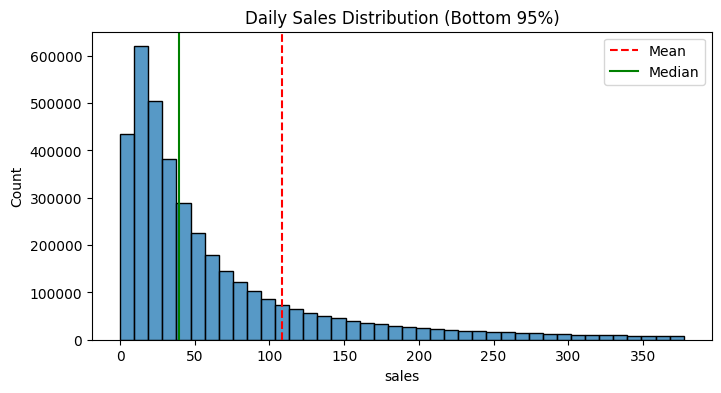

In [82]:
#mean and median of sales
mean_val = sales_train["sales"].mean()
median_val = sales_train["sales"].median()
print(f"Mean sales: {mean_val:.2f}")
print(f"Median sales: {median_val:.2f}")

# plot distribution up to the 95th percentile so outliers don't squash the histogram
upper_limit = sales_train["sales"].quantile(0.95)
plt.figure(figsize=(8, 4))
sns.histplot(sales_train[sales_train["sales"] <= upper_limit]["sales"], bins=40)
plt.axvline(mean_val, color="red", linestyle="--", label="Mean")
plt.axvline(median_val, color="green", label="Median")
plt.title("Daily Sales Distribution (Bottom 95%)")
plt.legend()
plt.show()

Sales are strongly right skewed: the mean (108.4) is almost 3 times the median (39.5). Most products sell a small amount each day and a few products sell a lot. We plotted only the bottom 95% so the histogram is readable.

### Sales by warehouse

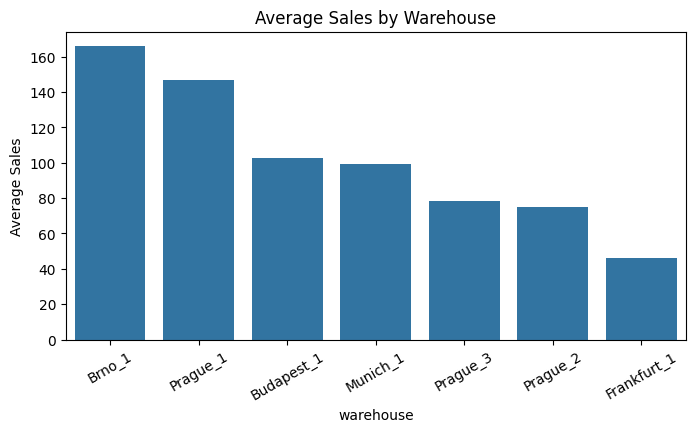

In [83]:
#average sales by warehouse
wh_sales = sales_train.groupby("warehouse")["sales"].mean().sort_values(ascending=False)
plt.figure(figsize=(8, 4))
sns.barplot(x=wh_sales.index, y=wh_sales.values)
plt.title("Average Sales by Warehouse")
plt.ylabel("Average Sales")
plt.xticks(rotation=30)
plt.show()

Brno_1 and Prague_1 have the highest average sales and Frankfurt_1 has the lowest. The warehouses are very different in size, so the warehouse is important information for prediction.

### Prices and orders by warehouse

In [84]:
#warehouses are in different countries so sell_price_main has different scales
sales_train.groupby("warehouse")[["sell_price_main", "total_orders", "sales"]].agg(["mean", "median", "min", "max"])

sell_price_main                         total_orders          \
                       mean  median   min       max         mean  median   
warehouse                                                                  
Brno_1            67.873869   44.64  1.63   1015.51  8196.958822  8241.0   
Budapest_1       918.184147  696.80  0.12  21682.99  5517.653329  5582.0   
Frankfurt_1        2.977863    2.20  0.18     50.15  1421.066435  1440.0   
Munich_1           3.002412    2.18  0.11     38.75  3181.274187  2960.0   
Prague_1          65.941507   43.86  1.66   1112.54  9114.406893  9252.0   
Prague_2          65.624530   43.66  0.02    994.18  4629.169859  4548.0   
Prague_3          67.141527   44.08  2.02    963.01  4862.602626  4861.0   

                                   sales                        
                min      max        mean median  min       max  
warehouse                                                       
Brno_1       2967.0  13867.0  165.814570  55.00  0.0  26316.19  
Budapest_1   2898.0   9277.0  102.934222  47.70  0.0   6231.23  
Frankfurt_1   798.0   2143.0   46.116097  27.31  0.0   1883.75  
Munich_1      458.0   7666.0   99.519923  54.50  0.0   3429.84  
Prague_1     2466.0  18475.0  146.635053  51.99  0.0  23957.36  
Prague_2     1633.0   9999.0   75.200678  25.71  0.0  12180.19  
Prague_3     1408.0   8429.0   78.314883  27.72  0.0  11549.61

The warehouses are in different countries, so prices are in different currencies: forint in Budapest (mean ~918), euro in Frankfurt and Munich (mean ~3) and koruna in Brno and Prague (mean ~66). We can't compare `sell_price_main` across warehouses directly, so we normalize it per warehouse.

## 6. Data Cleaning

- **Sales:** drop the 52 rows where `sales` and `total_orders` are missing, clip discounts to [0, 1], and add `max_discount` (the largest of the 7 discount types).
- **Calendar:** fill the 166 missing holiday names on real holidays with `"Unknown Holiday"` (we don't use `holiday_name` in the models, only the `holiday` flag) and set the name to `"No Holiday"` on other days.

In [85]:
#clean calendar and sales tables
cal_clean = clean_calendar(calendar)
train_clean = clean_sales(sales_train, is_train=True)
test_clean = clean_sales(sales_test, is_train=False)
print("Remaining missing values in train:", train_clean.isnull().sum().sum())
print("Remaining missing values in calendar:", cal_clean.isnull().sum().sum())

Remaining missing values in train: 0
Remaining missing values in calendar: 0


### Price normalization

We add `price_norm`, the min-max scaled price in each warehouse, so prices are between 0 and 1 in every country. The min and max are computed on the training set and applied to both train and test sets.

In [86]:
#normalize price per warehouse
train_norm, test_norm = normalize_price(train_clean, test_clean)
train_norm.groupby("warehouse")[["sell_price_main", "price_norm"]].agg(["min", "mean", "max"])

sell_price_main                       price_norm               
                        min        mean       max        min      mean  max
warehouse                                                                  
Brno_1                 1.63   67.873869   1015.51        0.0  0.065337  1.0
Budapest_1             0.12  918.184147  21682.99        0.0  0.042341  1.0
Frankfurt_1            0.18    2.977871     50.15        0.0  0.055991  1.0
Munich_1               0.11    3.002305     38.75        0.0  0.074853  1.0
Prague_1               1.66   65.941507   1112.54        0.0  0.057865  1.0
Prague_2               0.02   65.624530    994.18        0.0  0.065990  1.0
Prague_3               2.02   67.141527    963.01        0.0  0.067765  1.0

### Merging tables

We merge the sales data with `inventory` (product id and categories) on `unique_id` and with `calendar` (holiday, shop closure and school holiday flags) on `date` and `warehouse`. The number of rows doesn't change, so the merge didn't create duplicates.

In [87]:
#merge with inventory and calendar
print("Train shape before merge:", train_norm.shape)
train_merged = merge_tables(train_norm, inventory, cal_clean)
test_merged = merge_tables(test_norm, inventory, cal_clean)
del train_clean, train_norm
print("Train shape after merge:", train_merged.shape)
print("Test shape after merge:", test_merged.shape)
train_merged.head(3)

Train shape before merge: (4007367, 16)
Train shape after merge: (4007367, 23)
Test shape after merge: (47021, 21)


,unique_id,date,warehouse,total_orders,sales,sell_price_main,availability,type_0_discount,type_1_discount,type_2_discount,...,type_6_discount,max_discount,price_norm,product_unique_id,L1_category_name_en,L2_category_name_en,holiday,shops_closed,winter_school_holidays,school_holidays
0,4845,2024-03-10,Budapest_1,6436.0,16.34,646.26,1.0,0.0,0.0,0.0,...,0.0,0.15312,0.029800,2375,Bakery,Bakery_L2_18,0,0,0,0
1,4845,2021-05-25,Budapest_1,4663.0,12.63,455.96,1.0,0.0,0.0,0.0,...,0.0,0.15025,0.021023,2375,Bakery,Bakery_L2_18,0,0,0,0
2,4845,2021-12-20,Budapest_1,6507.0,34.55,455.96,1.0,0.0,0.0,0.0,...,0.0,0.15025,0.021023,2375,Bakery,Bakery_L2_18,0,0,0,0


## 7. EDA on the Merged Data

### Correlation matrix

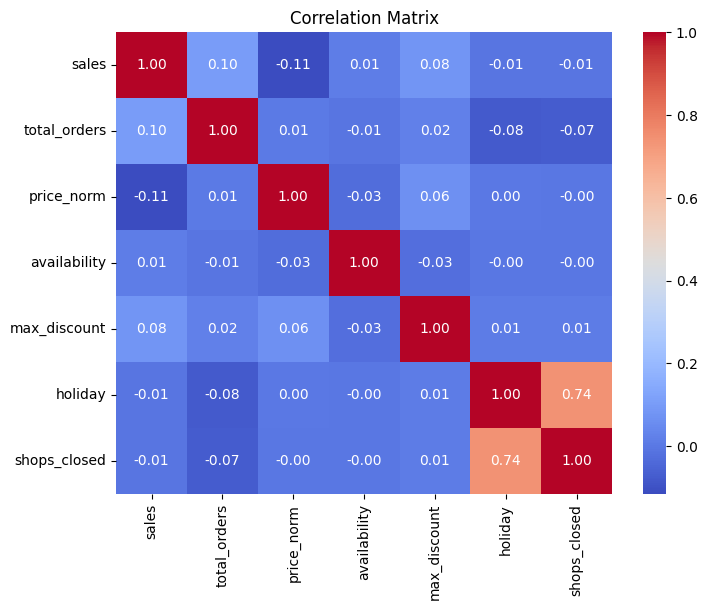

In [88]:
#correlation matrix
#sell_price_main is not used because it is in different currencies
#price_norm is used instead

cols = ["sales", "total_orders", "price_norm", "availability", "max_discount", "holiday", "shops_closed"]
plt.figure(figsize=(8, 6))
sns.heatmap(train_merged[cols].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Matrix")
plt.show()

None of the numeric features has a strong linear correlation with `sales`. The largest are `price_norm` (-0.11, cheaper products sell more), `total_orders` (0.10) and `max_discount` (0.08). `holiday` and `shops_closed` are strongly correlated with each other (0.74). Sales seem to depend mostly on *which product* it is and on time, not on these features alone.

We left out `sell_price_main` here because it is in different currencies, so its correlation would not mean much. `price_norm` is used instead.

### Sales by product category

From `inventory.csv`, we merged `L1_category_name_en` and `L2_category_name_en`. Below we check the sales statistics for the 3 main (`L1`) categories and plot the top 5 `L2` categories.

In [89]:
#sales summary for L1 categories
train_merged.groupby("L1_category_name_en")["sales"].agg(["count", "mean", "median"])

,count,mean,median
L1_category_name_en,,,
Bakery,1492850,121.769964,36.01
Fruit and vegetable,2023667,114.425299,48.80
Meat and fish,490850,42.739045,25.01


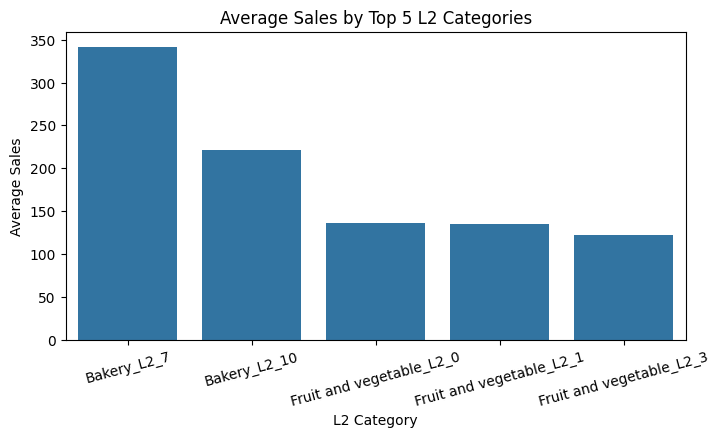

In [90]:
#average sales for top 5 L2 categories
l2_sales = train_merged.groupby("L2_category_name_en")["sales"].mean().sort_values(ascending=False).head(5)
plt.figure(figsize=(8, 4))
sns.barplot(x=l2_sales.index, y=l2_sales.values)
plt.title("Average Sales by Top 5 L2 Categories")
plt.ylabel("Average Sales")
plt.xlabel("L2 Category")
plt.xticks(rotation=15)
plt.show()

`Fruit and vegetable` has the most rows and the highest median sales (48.8), while `Bakery` has the highest mean sales (121.8) because some bakery subcategories (`Bakery_L2_7`) sell in large daily quantities. `Meat and fish` is much smaller and has the lowest average sales (42.7).

### Sales over time

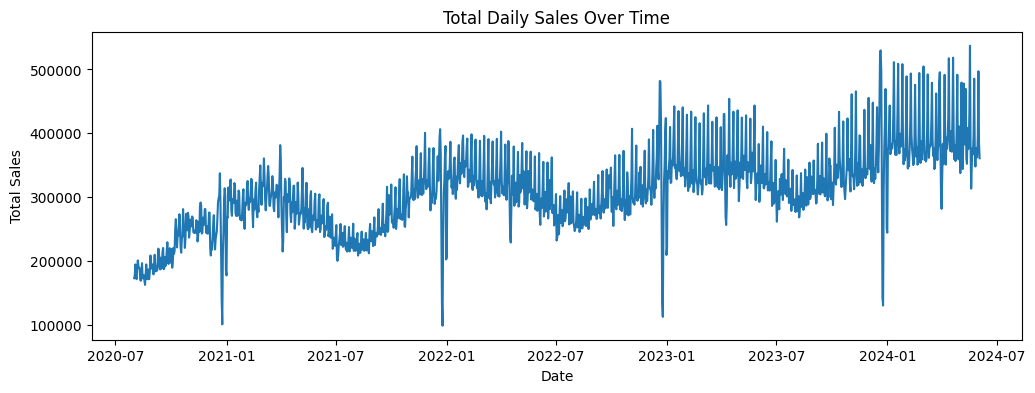

In [91]:
#total daily sales over time
daily_sales = train_merged.groupby("date")["sales"].sum()
daily_sales.index = pd.to_datetime(daily_sales.index)
plt.figure(figsize=(12, 4))
plt.plot(daily_sales.index, daily_sales.values)
plt.title("Total Daily Sales Over Time")
plt.xlabel("Date")
plt.ylabel("Total Sales")
plt.show()

- Total daily sales increase over the years, from about 200k in 2020 to about 400k in 2024.
- There is a sharp drop at the end of every year (Christmas and New Year) and a peak just before it.
- Sales are a bit lower in summer.
- The line moves up and down every week, so there is a weekly pattern.

Because of the upward trend, recent data should be more useful than old data for predicting the test period.

### Sales by day of week

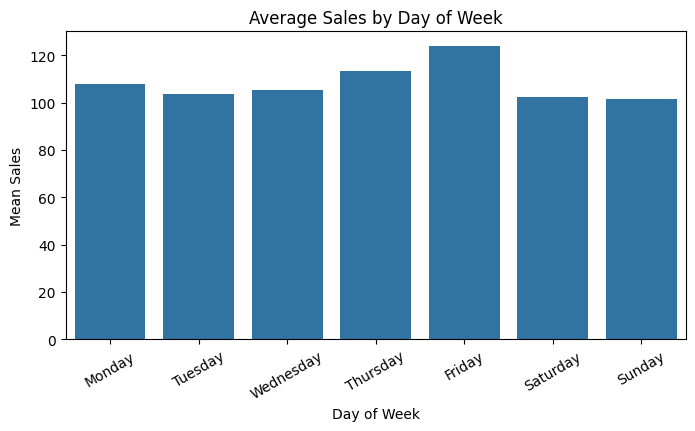

In [92]:
#average sales by day of week
train_merged["day_name"] = pd.to_datetime(train_merged["date"]).dt.day_name()
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
day_sales = train_merged.groupby("day_name")["sales"].mean().reindex(day_order)
plt.figure(figsize=(8, 4))
sns.barplot(x=day_sales.index, y=day_sales.values)
plt.title("Average Sales by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Mean Sales")
plt.xticks(rotation=30)
plt.show()

Friday has the highest average sales (124), followed by Thursday. Saturday and Sunday are the lowest. Customers probably order before the weekend.

### Holidays vs regular days

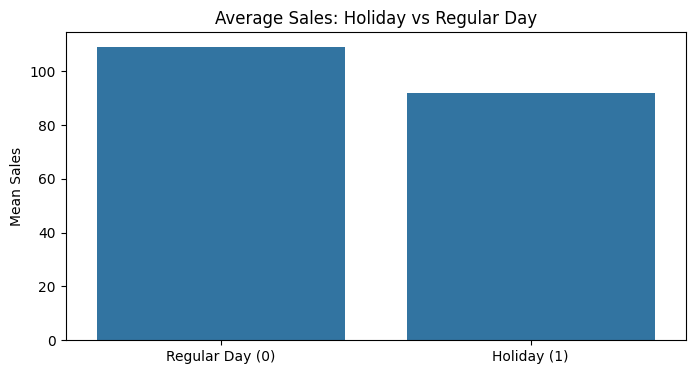

In [93]:
#average sales on holidays vs regular days
hol_sales = train_merged.groupby("holiday")["sales"].mean()
plt.figure(figsize=(8, 4))
sns.barplot(x=["Regular Day (0)", "Holiday (1)"], y=hol_sales.values)
plt.title("Average Sales: Holiday vs Regular Day")
plt.ylabel("Mean Sales")
plt.show()

Average sales are lower on holidays (92) than on regular days (109). This makes sense because shops are often closed on holidays (the correlation between `holiday` and `shops_closed` is 0.74).

### Effect of discounts

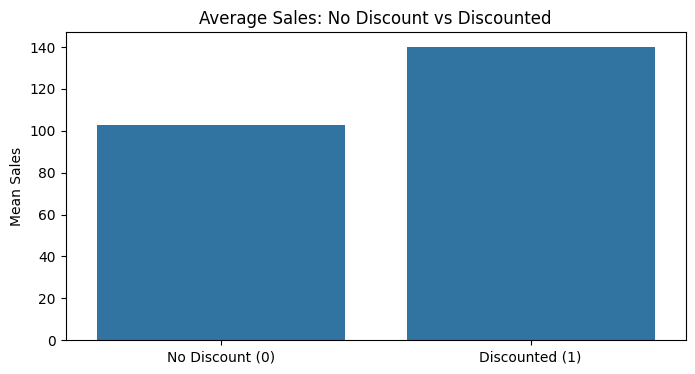

In [94]:
#average sales with discount vs no discount
train_merged["has_discount"] = (train_merged["max_discount"] > 0).astype(int)
disc_sales = train_merged.groupby("has_discount")["sales"].mean()
plt.figure(figsize=(8, 4))
sns.barplot(x=["No Discount (0)", "Discounted (1)"], y=disc_sales.values)
plt.title("Average Sales: No Discount vs Discounted")
plt.ylabel("Mean Sales")
plt.show()

Discounted products sell more on average (140 vs 103). Next we check whether this depends on the size of the discount.

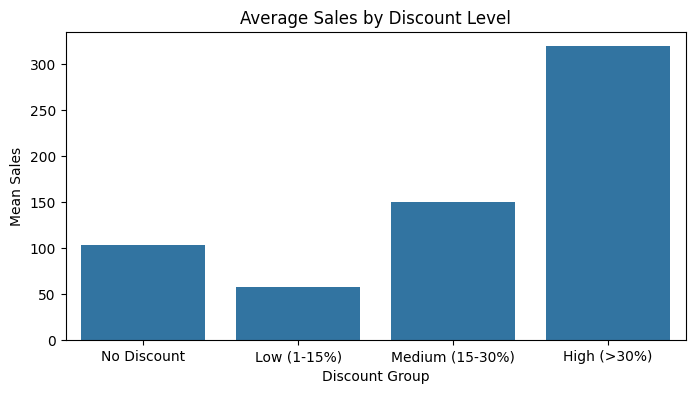

In [95]:
#average sales by discount level
train_merged["discount_group"] = pd.cut(
    train_merged["max_discount"],
    bins=[-0.01, 0.0, 0.15, 0.30, 1.0],
    labels=["No Discount", "Low (1-15%)", "Medium (15-30%)", "High (>30%)"]
)
disc_sales = train_merged.groupby("discount_group", observed=False)["sales"].mean()
plt.figure(figsize=(8, 4))
sns.barplot(x=disc_sales.index, y=disc_sales.values)
plt.title("Average Sales by Discount Level")
plt.xlabel("Discount Group")
plt.ylabel("Mean Sales")
plt.show() #discount vs no discount looks like discount always helps, check by discount level

The result is not simple:
- Low discounts (1-15%) have lower average sales (58) than no discount (103).
- Medium discounts (15-30%) are higher (150), and high discounts (>30%) are much higher (320).

However, this plot compares different products across discount groups, and low discounts may be used mostly on products that normally sell less. Below we compare each product with its own average sales to remove this product mix effect.

discount_group
No Discount        0.931802
Low (1-15%)        0.993386
Medium (15-30%)    1.406012
High (>30%)        2.420200
Name: norm_sales, dtype: float64


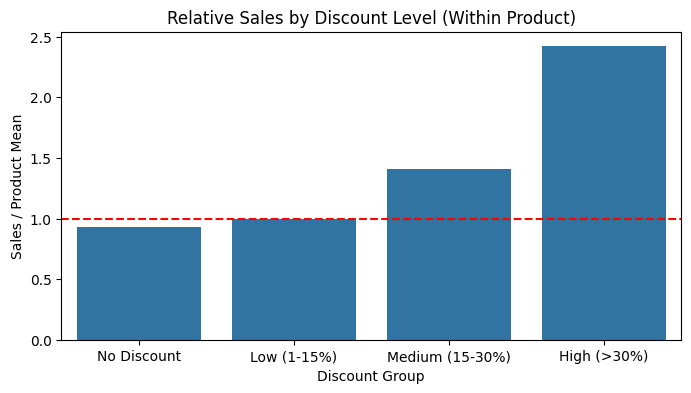

In [96]:
#discount groups have different products, so divide each sale by the product's own average
product_mean = train_merged.groupby("unique_id")["sales"].mean()
train_merged["norm_sales"] = train_merged["sales"] / train_merged["unique_id"].map(product_mean)
disc_norm = train_merged.groupby("discount_group", observed=False)["norm_sales"].mean()
print(disc_norm)

plt.figure(figsize=(8, 4))
sns.barplot(x=disc_norm.index, y=disc_norm.values)

plt.axhline(1, color="red", linestyle="--") #1 means normal sales of the product
plt.title("Relative Sales by Discount Level (Within Product)")
plt.xlabel("Discount Group")
plt.ylabel("Sales / Product Mean")
plt.show()

When we compare each product with its own mean sales (`1.0` = normal sales for that product), relative sales increase with the discount level. This shows that discounts boost sales for a given product, and the lower raw average in the `1-15%` group above was caused by product mix.

We also check the 7 discount columns (`type_0_discount` to `type_6_discount`) one by one to see which discount types increase relative sales the most when they are active (`> 0`).

type_0_discount -> relative sales: 2.61
type_1_discount -> relative sales: 1.31
type_2_discount -> relative sales: 2.20
type_3_discount -> relative sales: 1.01
type_4_discount -> relative sales: 1.05
type_5_discount -> relative sales: 1.38
type_6_discount -> relative sales: 0.92


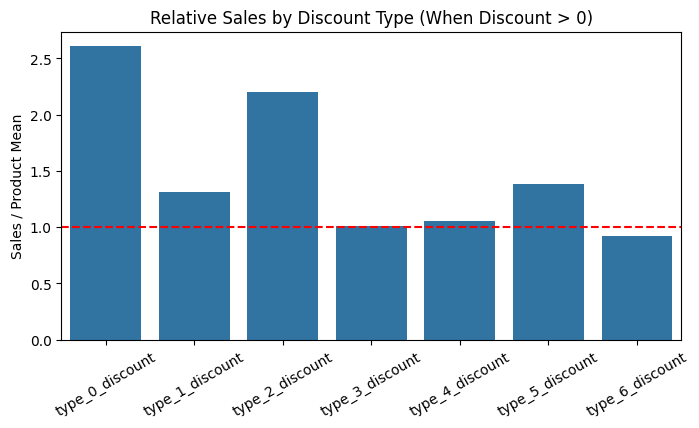

In [97]:
#check average relative sales for each of the 7 discount types when active
discount_cols = [f"type_{i}_discount" for i in range(7)]
discount_lift = {}
for col in discount_cols:
    avg_ratio = train_merged[train_merged[col] > 0]["norm_sales"].mean()
    discount_lift[col] = avg_ratio
    print(f"{col} -> relative sales: {avg_ratio:.2f}")

plt.figure(figsize=(8, 4))
sns.barplot(x=list(discount_lift.keys()), y=list(discount_lift.values()))
plt.axhline(1, color="red", linestyle="--") #1 means normal sales of the product
plt.title("Relative Sales by Discount Type (When Discount > 0)")
plt.ylabel("Sales / Product Mean")
plt.xticks(rotation=30)
plt.show()

`type_0_discount` (2.61) and `type_2_discount` (2.20) more than double a product's normal sales, while `type_3`, `type_4` and `type_6` stay close to 1.0.

## 8. Validation Setup

First we check the date ranges of the train and test sets.

In [98]:
#check date ranges of train and test
print("Train dates:", sales_train["date"].min(), "-", sales_train["date"].max())
print("Test dates:", sales_test["date"].min(), "-", sales_test["date"].max())
print("Test days:", sales_test["date"].nunique())

Train dates: 2020-08-01 - 2024-06-02
Test dates: 2024-06-03 - 2024-06-16
Test days: 14


The test period is the 14 days right after the training data ends. To copy this, we use the last 14 days of the training data as validation and train only on the days before them. We also keep only the products in `test_weights.csv` and use their weights to compute WMAE, the competition metric. We also report MAE and RMSE.

## 9. Baseline Models

Historical mean / median: predict the average (or median) sales of each product over the whole training period. If a product is not in the training part, we use the global mean or median.

In [99]:
#split last 14 days for validation
train_part, val_part = split_train_val(train_merged, val_days=14)
#keep only products that are in test_weights
val_part = val_part.merge(test_weights, on="unique_id", how="inner")
print("Train part shape:", train_part.shape)
print("Val part shape:", val_part.shape)
#evaluate historical mean and median baselines
baseline_results, pred_mean, pred_median = train_baseline_models(train_part, val_part)
baseline_results

Train part shape: (3960048, 27)
Val part shape: (47319, 28)


,WMAE,MAE,RMSE
Historical Mean,33.2472,41.3242,140.8623
Historical Median,32.7647,41.3791,149.4606


Three more baselines:
- Ridge regression with `price_norm`, `max_discount`, `holiday`, `shops_closed` and `school_holidays`. (`availability` is left out because it is not in the test set.) It doesn't know which product it is predicting.
- Recent mean (28 days): the mean sales of each product in the last 28 days only. We tried this because of the upward trend in the time series plot.
- Recent median (28 days): the median sales of each product in the last 28 days, so that high sales spikes in the last 4 weeks don't pull the prediction up.

In [100]:
#ridge regression and recent 28-day baselines for comparison
y_val = val_part["sales"].values
val_w = val_part["weight"].values
pred_ridge = predict_ridge_baseline(train_part, val_part)
#daily sales plot shows an upward trend, so use only the last 28 days per product
pred_recent = predict_recent_mean_baseline(train_part, val_part)
pred_recent_med = predict_recent_median_baseline(train_part, val_part)
all_results = pd.DataFrame([
    calculate_metrics(y_val, pred_mean, val_w),
    calculate_metrics(y_val, pred_median, val_w),
    calculate_metrics(y_val, pred_ridge, val_w),
    calculate_metrics(y_val, pred_recent, val_w),
    calculate_metrics(y_val, pred_recent_med, val_w)
], index=["Historical Mean", "Historical Median", "Ridge Regression", "Recent Mean (28 days)", "Recent Median (28 days)"])
all_results

,WMAE,MAE,RMSE
Historical Mean,33.2472,41.3242,140.8623
Historical Median,32.7647,41.3791,149.4606
Ridge Regression,74.9179,113.1264,397.6932
Recent Mean (28 days),31.2676,34.8699,111.1344
Recent Median (28 days),26.7680,31.4962,113.5772


**Results:**
- Recent median (28 days) has the best WMAE (26.77) and MAE (31.50), followed by Recent mean (28 days) (WMAE 31.27, RMSE 111.13). Since sales grow over time, the last 4 weeks are much closer to the validation period than the full history.
- For both the full history and the last 28 days, the median gives a better WMAE than the mean, but a slightly higher RMSE. The median is less affected by big discount peaks, which helps the absolute error.
- Ridge is by far the worst (WMAE 74.92) because it has no information about the product, and product identity is the most important factor for sales.
- None of these baselines changes its prediction from day to day, so the weekly pattern isn't used yet.

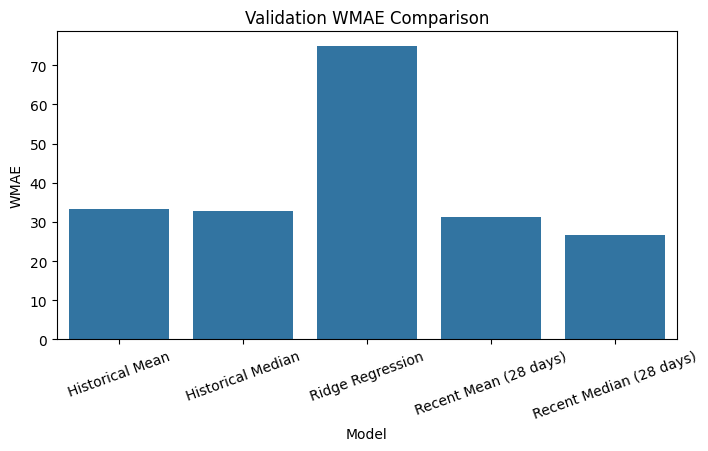

In [101]:
#plot wmae comparison for baselines
plt.figure(figsize=(8, 4))
sns.barplot(x=all_results.index, y=all_results["WMAE"].values)
plt.title("Validation WMAE Comparison")
plt.ylabel("WMAE")
plt.xlabel("Model")
plt.xticks(rotation=20)
plt.show()

## 10. Kaggle Submission

We use the best baseline, the 28-day recent median, on the test set. This time the median is computed on the **full** training data, so the last 28 days before the test period are used.

In [102]:
#save submission file using recent median (best wmae on validation)
test_preds = predict_recent_median_baseline(train_merged, test_merged)
sub = save_submission(test_merged, test_preds, filename="submission_recent_median.csv")
print("Submission shape:", sub.shape)
sub.head(5)

Submission shape: (47021, 2)


,id,sales_hat
0,1226_2024-06-03,23.095
1,1226_2024-06-11,23.095
2,1226_2024-06-13,23.095
3,1226_2024-06-15,23.095
4,1226_2024-06-09,23.095


In [103]:
#submit to kaggle as late submission
!kaggle competitions submit -c rohlik-sales-forecasting-challenge-v2 -f submission_recent_median.csv -m "recent median 28 days baseline"

100% 1.10M/1.10M [00:00<00:00, 1.81MB/s]
Successfully submitted to Rohlik Sales Forecasting Challenge

In [106]:
#check submission score
!kaggle competitions submissions -c rohlik-sales-forecasting-challenge-v2

fileName                      date                        description                      status                     publicScore  privateScore  
----------------------------  --------------------------  -------------------------------  -------------------------  -----------  ------------  
submission_recent_median.csv  2026-11-12 12:28:24.257000  recent median 28 days baseline   SubmissionStatus.COMPLETE  28.87416     28.26044      
submission_recent_median.csv  2026-11-12 12:09:58.090000  recent median 28 days baseline   SubmissionStatus.COMPLETE  28.87416     28.26044      
submission_recent_median.csv  2026-11-10 02:46:18.280000  recent median 28 days baseline   SubmissionStatus.COMPLETE  28.87416     28.26044      
submission_recent_median.csv  2026-11-09 20:26:25         recent median 28 days baseline   SubmissionStatus.COMPLETE  28.87416     28.26044      
submission_baseline.csv       2026-11-09 05:23:38.767000  recent mean 28 days baseline     SubmissionStatus.COMPLETE  32.888

## Conclusion

| Model | Validation WMAE |
|---|---|
| Historical Mean | 33.25 |
| Historical Median | 32.76 |
| Ridge Regression | 74.92 |
| Recent Mean (28 days) | 31.27 |
| **Recent Median (28 days)** | **26.77** |

Using the last 28 days instead of the full history improved the predictions a lot, and the 28-day median gave the lowest validation WMAE (26.77). On Kaggle, our 28-day recent median submission achieved **28.87** public and **28.26** private WMAE (improving over the 28-day recent mean score of 32.89 public / 31.84 private). Both scores match our validation ranking closely, confirming that our 14-day validation setup represents the test period well.

**Plan for Assignment 2:**
- Add calendar features (day of week, month, days before holidays) to use the weekly and yearly patterns
- Add lag and rolling features for each product
- Use product, category and warehouse information, plus the individual discount types (`type_0`, `type_2`)
- Try tree based models (e.g. LightGBM / Gradient Boosting) that can learn non-linear effects like the discount effect